# Stage 1: MH107, 480-gene panel

Raw Xenium data → QC → normalisation → gene-set scoring → `cell_class_threshold` → Nhood enrichment.

Labels in this sample come from scoring alone. PCA, UMAP and clusters are loaded or rebuilt from the saved object for review only.

## Parameters

In [1]:
SAMPLE = "MH107_480"

# Folders: set these before running
RAW_DATA_DIR = "/path/to/raw_xenium"  # one subfolder per sample, with cell_feature_matrix.h5 and cells.csv
SAVED_OBJECT_DIR = "/path/to/saved_objects"
LABEL_TABLE_DIR = "/path/to/label_tables"
OUTPUT_ROOT = "/path/to/stage1_output"

# Inputs (read only)
RAW_DIR = f"{RAW_DATA_DIR}/{SAMPLE}"
SAVED_OBJECT = f"{SAVED_OBJECT_DIR}/{SAMPLE}.h5ad"
COUNTS_CSV = f"{LABEL_TABLE_DIR}/{SAMPLE}.csv"

# Outputs
OUTPUT_DIR = f"{OUTPUT_ROOT}/{SAMPLE}"

# Seeds
GLOBAL_SEED = 36
NHOOD_SEED = 112233

# QC
CROP = None
GENES_TO_REMOVE = ["LGALS3"]
MIN_COUNTS = 15
MIN_CELLS = 5

# Clustering
N_NEIGHBORS = 15
LEIDEN_RESOLUTION = 1.5
LEIDEN_KEY = f"leiden_{LEIDEN_RESOLUTION}"

# Gene-set scoring
SCORE_QUANTILE = 0.7
LABEL_KEY = "cell_class_threshold"

# Nhood enrichment
RADIUS_UM = 50

# Marker genes for reviewing labels
label_markers = ["KRT19", "MUC1", "KRT7", "KRT8", "EPCAM", "FCGR3B", "SPP1", "CSTB", "HK2", "SLC2A1", "CXCL14", "COL11A1", "MMP11", "INHBA", "PDGFRA", "C7", "CXCL12", "ABCA8", "APOD", "OLR1", "HBEGF", "CD163", "C1QC", "C1QA", "C1QB", "F13A1", "CSF1R", "CD86", "HLA-DRB1", "HLA-DRA", "HLA-DPA1"]

# Cluster annotation
cluster_anno = {
    "0": "CAFs_MYO",
    "1": "Malignant cells",
    "2": "Malignant cells",
    "3": "TAMs_C1QC",
    "4": "Mixed_Mast_CAFs",
    "5": "CAFs_MYO",
    "6": "CAFs_NRT",
    "7": "Endothelial",
    "8": "Malignant cells",
    "9": "TAMs_C1QC",
    "10": "CAFs_MYO",
    "11": "Hypoxia",
    "12": "Ductal MUC5B",
    "13": "T cells",
    "14": "Malignant cells",
    "15": "Malignant cells",
    "16": "Mixed cells",
    "17": "Malignant cells",
    "18": "CAFs_NRT",
    "19": "Endocrine",
    "20": "Ductal MUC5B",
    "21": "Malignant cells",
    "22": "T cells",
    "23": "vSMCs",
    "24": "Acinar_REG",
    "25": "Plasma",
    "26": "Schwann/Neuron"}

# Gene sets
gene_sets = {
    'Malignant cells': ['KRT19', 'KRT17','KRT7','S100A2','SLC2A1','ENO2'],
    'Ductal MUC5B': ['REG1A','CFTR','SLC4A4','MUC5B','MUC6','ONECUT2','CRP'],
    'Ductal' : ['CFTR','SLC4A4','PKHD1','CRP'],
    'Acinar_REG+': ['PRSS1','CTRC','REG3G','REG3G','REG3A'],
    'Tuft' : ['AVIL','BMX','TRPM5'],
    'Endocrine': ['PPY','INS'],
    'FDCs': ['FDCSP','VCAM1','SLC1A2','CXCL13'],
    'FRCs': ['PLA2G2A','PDPN','IL1R1','MEDAG','IGF1','CSF1'],
    'LECs': ['LYVE1','FLT4','PROX1'],
    'Endothelial' : ['VWF','PLVAP','FLT1'],
    'SMCs' : ['MYH11'],
    'Pericytes': ['PDGFRB','RGS5','TRPC6'],
    'Schwann': ['SOX10','CDH19','CHL1','NGFR'],
    'Neurons': ['SYT1','TAC1'],
    'Adipocytes': ['PLIN1','LIPE','ADIPOQ'],
    'CAFs_MYO': ['COL11A1','POSTN',"MMP11"],
    'CAFs_CXCL14': ['COL11A1','CXCL14',"MMP11"],
    'CAFs_NRT' : ['PDGFRA','SCN7A','C7','ABCA8','ABCA10','APOD','ABCA8'],
    'NK': ['GNLY', 'NKG7','KLRC1'],
    'CD4 T cells': ['IL7R','CD4','TCF7'],
    'CD4 Treg' : ['FOXP3','IKZF2','CCR8'],
    'CD4 Tfh' : ['CD4','ICOS','CD40LG'],
    'CD8 T cells': ['CD8A','CD8B','GZMB','GZMA'],
    'CD8 TRM' : ['CD8A','CD8B','ITGAE','ITGA1','STK17B','ID2','CD226'],
    'B cells': ['MS4A1','CD19','CD22'],
    'Plasma': ['MZB1','JCHAIN','IGKC'],
    'gdT' : ['XCL1','TRGC1','TRGC2'],
    'Neutrophils': ['CSF3R','TREM1','FCGR3B'],
    'DC1' : ['CLEC9A','IRF8','IDO1'],
    'DC2' : ['CLEC10A','CD1C'],
    'pDCs' : ['LILRA4','IL3RA'],
    'Migratory DCs' : ['CCL22','LAMP3'],
    'Mast' : ['CPA3','KIT','TPSAB1'],
    'TAMs_SPP1' : ['SPP1','LIPA','MARCO','HK2','CSTB'],
    'TAMs_OLR1' : ['OLR1','HBEGF'],
    'TAMs_C1QC' : ['C1QC','SELENOP','C1QA','F13A1','CD163'],
    'TAMs_MHC' : ['CD86','HLA-DRB1','HLA-DRB5','CSF1R']
}

In [2]:
import importlib
import os
import random
import sys

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq

np.random.seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)

assert os.path.exists(SAVED_OBJECT), f"Saved object not found: {SAVED_OBJECT}"
assert os.path.dirname(SAVED_OBJECT) != OUTPUT_DIR, "OUTPUT_DIR must not hold the saved object"
os.makedirs(OUTPUT_DIR, exist_ok=True)

packages = ["scanpy", "squidpy", "anndata", "numpy", "scipy", "pandas", "sklearn", "umap", "pynndescent",
            "numba", "leidenalg", "igraph", "h5py", "matplotlib", "seaborn"]
software = pd.DataFrame(
    [(p, getattr(importlib.import_module(p), "__version__", "unknown")) for p in packages],
    columns=["package", "version"],
)
software.to_csv(os.path.join(OUTPUT_DIR, "software_versions.tsv"), sep="\t", index=False)
print("python:", sys.version)
display(software)

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


python: 3.9.18 (main, Sep 11 2023, 13:41:44) 
[GCC 11.2.0]


,package,version
0,scanpy,1.9.5
1,squidpy,1.3.1
2,anndata,0.10.8
3,numpy,1.24.4
4,scipy,1.9.1
5,pandas,2.3.3
6,sklearn,1.3.2
7,umap,0.5.4
8,pynndescent,0.5.10
9,numba,0.60.0


## 1. Load raw data and QC

In [3]:
adata = sc.read_10x_h5(os.path.join(RAW_DIR, "cell_feature_matrix.h5"))
df = pd.read_csv(os.path.join(RAW_DIR, "cells.csv"))
df.set_index(adata.obs_names, inplace=True)
adata.obs = df.copy()
adata.obsm["spatial"] = adata.obs[["x_centroid", "y_centroid"]].copy().to_numpy()
print(f"Raw: {adata.n_obs} cells")

if CROP is not None:
    criteria = (
        (adata.obs["x_centroid"] >= CROP["x_min"]) & (adata.obs["x_centroid"] <= CROP["x_max"]) &
        (adata.obs["y_centroid"] >= CROP["y_min"]) & (adata.obs["y_centroid"] <= CROP["y_max"])
    )
    adata = adata[criteria, :].copy()
    print(f"After crop: {adata.n_obs} cells")

Raw: 219400 cells


~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be

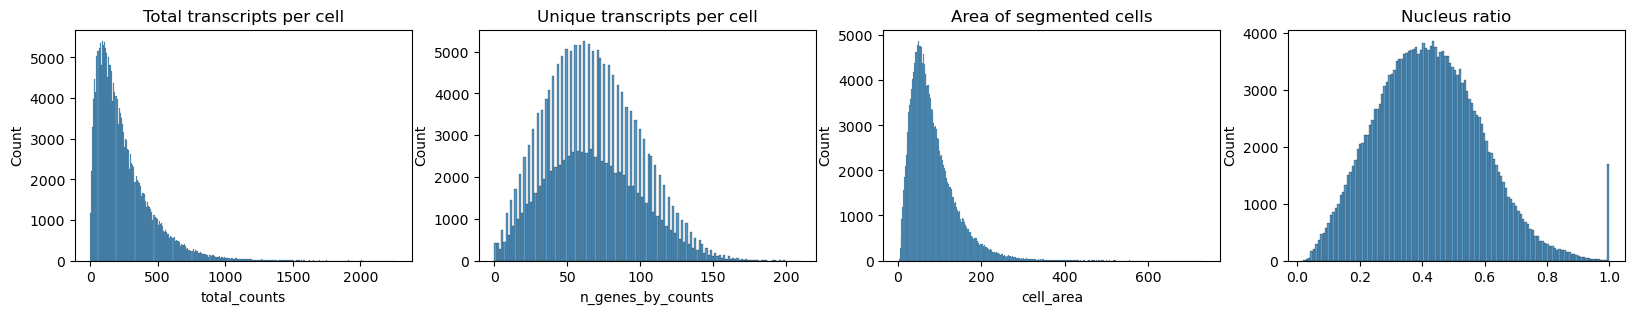

After QC: 214226 cells, 479 genes


In [4]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

fig, axs = plt.subplots(1, 4, figsize=(20, 3))
axs[0].set_title("Total transcripts per cell")
sns.histplot(adata.obs["total_counts"], kde=False, ax=axs[0])
axs[1].set_title("Unique transcripts per cell")
sns.histplot(adata.obs["n_genes_by_counts"], kde=False, ax=axs[1])
axs[2].set_title("Area of segmented cells")
sns.histplot(adata.obs["cell_area"], kde=False, ax=axs[2])
axs[3].set_title("Nucleus ratio")
sns.histplot(adata.obs["nucleus_area"] / adata.obs["cell_area"], kde=False, ax=axs[3])
plt.show()

if GENES_TO_REMOVE:
    adata = adata[:, ~adata.var_names.isin(GENES_TO_REMOVE)].copy()

sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)
print(f"After QC: {adata.n_obs} cells, {adata.n_vars} genes")

## 2. Normalisation

In [5]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)

# Scaled values are kept for plotting only
adata.layers["scaled"] = sc.pp.scale(adata, copy=True).X

## 3. Review of tissue and cell quality

~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
~/.local/lib/python3.9/site-packages/scanpy/plotting/_tools/scat

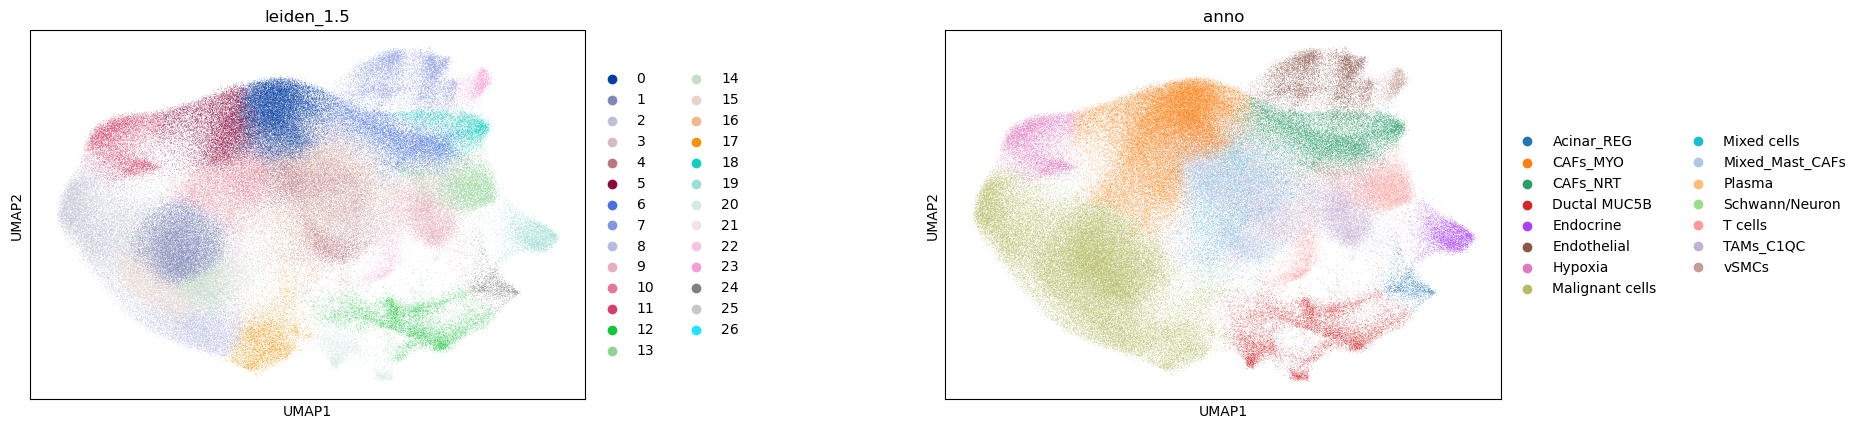

~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


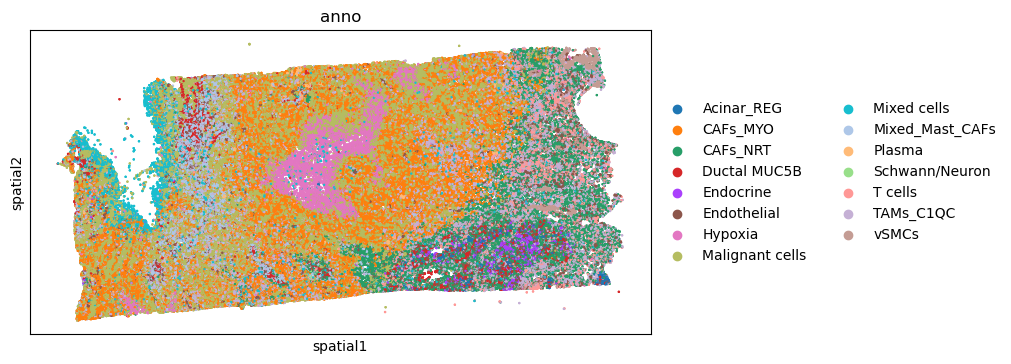

In [6]:
saved = sc.read_h5ad(SAVED_OBJECT, backed="r")
assert list(saved.obs_names) == list(adata.obs_names), "Saved object does not have the same cells in the same order"
assert list(saved.var_names) == list(adata.var_names), "Saved object does not have the same genes in the same order"

adata.obsm["X_pca"] = np.asarray(saved.obsm["X_pca"])
adata.obsm["X_umap"] = np.asarray(saved.obsm["X_umap"])
adata.varm["PCs"] = np.asarray(saved.varm["PCs"])
adata.uns["pca"] = {key: np.asarray(value) if not isinstance(value, dict) else dict(value)
                    for key, value in saved.uns["pca"].items()}
saved.file.close()

sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, random_state=GLOBAL_SEED)
sc.tl.leiden(adata, resolution=LEIDEN_RESOLUTION, key_added=LEIDEN_KEY, random_state=GLOBAL_SEED)

clusters_found, clusters_mapped = set(adata.obs[LEIDEN_KEY].cat.categories), set(cluster_anno)
assert clusters_found == clusters_mapped, f"Clusters differ from cluster_anno: {sorted(clusters_found ^ clusters_mapped)}"
adata.obs["anno"] = adata.obs[LEIDEN_KEY].map(cluster_anno).astype("category")

sc.pl.umap(adata, color=[LEIDEN_KEY, "anno"], wspace=0.5)
sq.pl.spatial_scatter(adata, library_id="spatial", shape=None, color=["anno"], size=2, figsize=(10, 10))

## 4. Gene-set scoring and labels

In [7]:
def assign_labels(data):
    """Score the gene sets, then give each cell its top label if the score reaches the threshold."""
    for cell_type, genes in gene_sets.items():
        sc.tl.score_genes(data, gene_list=genes, score_name=f"{cell_type}_score")

    columns = [f"{cell_type}_score" for cell_type in gene_sets.keys()]
    scores = data.obs[columns]
    threshold = scores.quantile(SCORE_QUANTILE).max()  # the highest SCORE_QUANTILE quantile across all gene sets

    data.obs["max_score"] = scores.max(axis=1)
    labels = scores.idxmax(axis=1).str.replace("_score", "")
    labels[data.obs["max_score"] < threshold] = "Unclassified"
    return threshold, labels, columns


threshold, base_labels, score_columns = assign_labels(adata)
print(f"Threshold: {threshold}")
print(f"Cells below threshold: {int((base_labels == 'Unclassified').sum())} of {adata.n_obs}")


Threshold: 0.4223370659458745
Cells below threshold: 10061 of 214226


In [8]:
def final_labels(labels, anno):
    return labels.astype("category")


adata.obs[LABEL_KEY] = final_labels(base_labels, adata.obs["anno"].astype(str))
print(adata.obs[LABEL_KEY].value_counts())

cell_class_threshold
Malignant cells    48529
CAFs_MYO           46995
Ductal MUC5B       12972
Mast               10177
Unclassified       10061
Endocrine           8629
TAMs_C1QC           7501
CAFs_NRT            6972
Pericytes           6344
SMCs                6219
Endothelial         6151
Neutrophils         5539
TAMs_SPP1           5176
Ductal              4317
Plasma              3877
TAMs_MHC            3576
Acinar_REG+         3456
CD4 T cells         2435
CAFs_CXCL14         2406
CD8 T cells         2087
TAMs_OLR1           1643
FRCs                1478
NK                   984
Migratory DCs        787
DC2                  708
DC1                  643
pDCs                 615
LECs                 608
gdT                  601
CD4 Treg             448
Schwann              394
B cells              358
FDCs                 332
CD8 TRM              318
Adipocytes           259
Neurons              254
CD4 Tfh              216
Tuft                 161
Name: count, dtype: int64


~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:483: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_map)
~/.local/lib/python3.9/site-packages/squidpy/pl/_spatial_utils.py:956: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


categories: Acinar_REG+, Adipocytes, B cells, etc.
var_group_labels: Malignant cells, Ductal MUC5B, Ductal, etc.


~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
~/.local/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


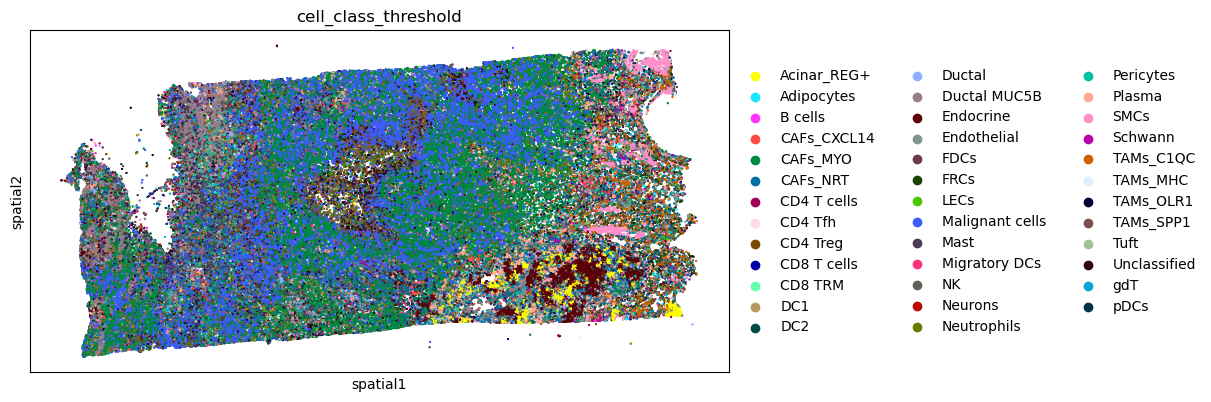

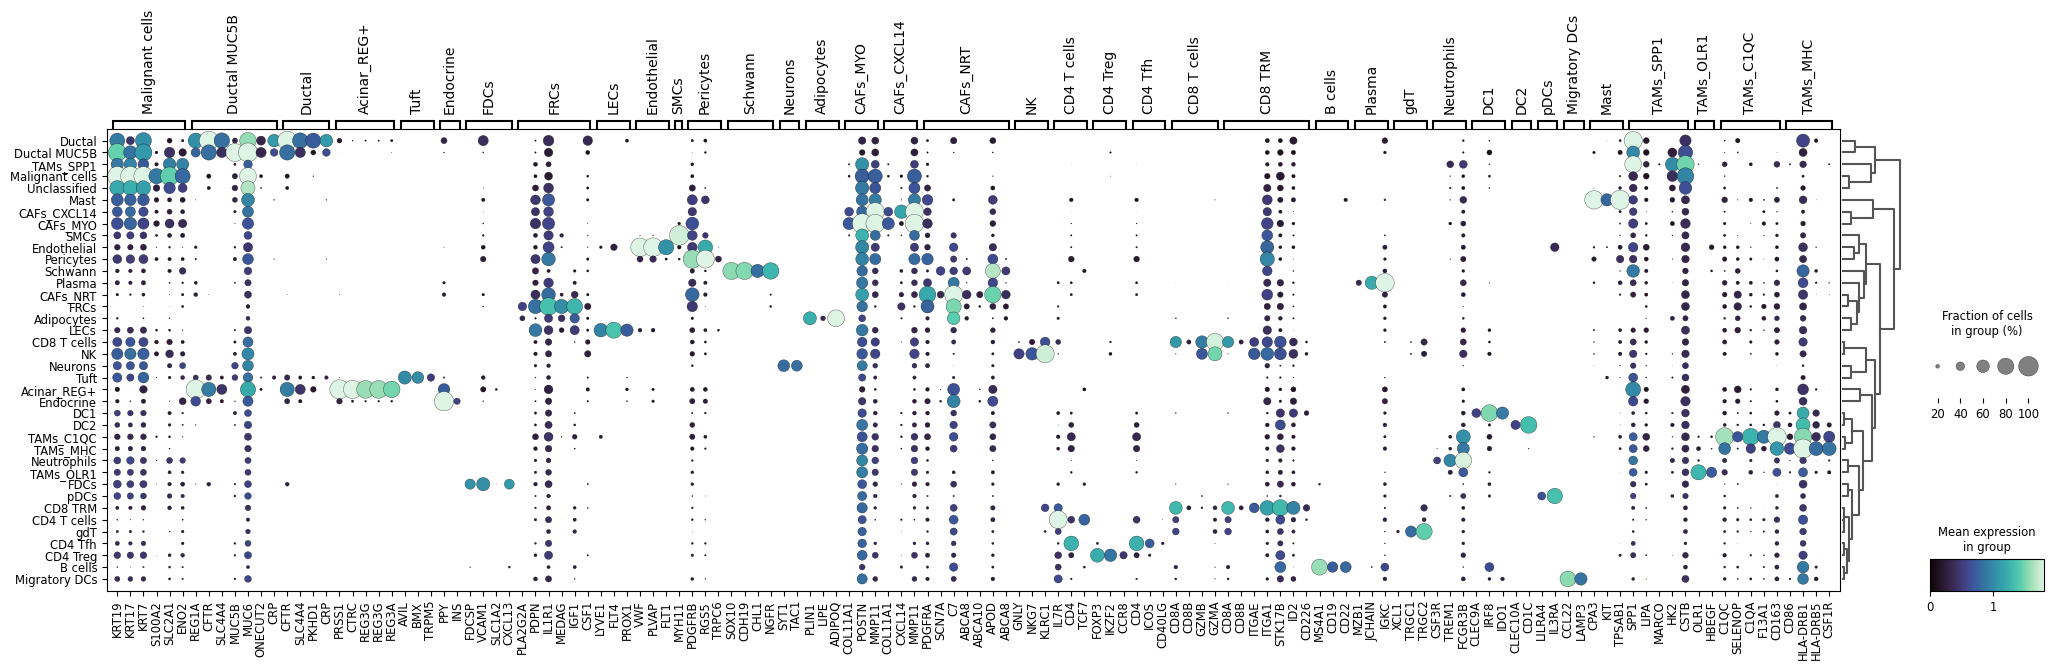

In [13]:
sq.pl.spatial_scatter(adata, shape=None, color=[LABEL_KEY], size=1, library_id="spatial", figsize=(12, 10))

sc.pl.dotplot(adata, var_names=gene_sets, groupby=LABEL_KEY,
              figsize=(25, 6), vmax=1.8, vmin=0, dot_min=0.1, cmap="mako", dendrogram=True)

## 5. Nhood enrichment

  0%|          | 0/1000 [00:00<?, ?/s]

~/miniconda3/envs/xenium.squidpy/lib/python3.9/site-packages/anndata/_core/anndata.py:430: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(
~/.local/lib/python3.9/site-packages/squidpy/pl/_utils.py:556: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  row_labels = adata.obs[key][row_order]


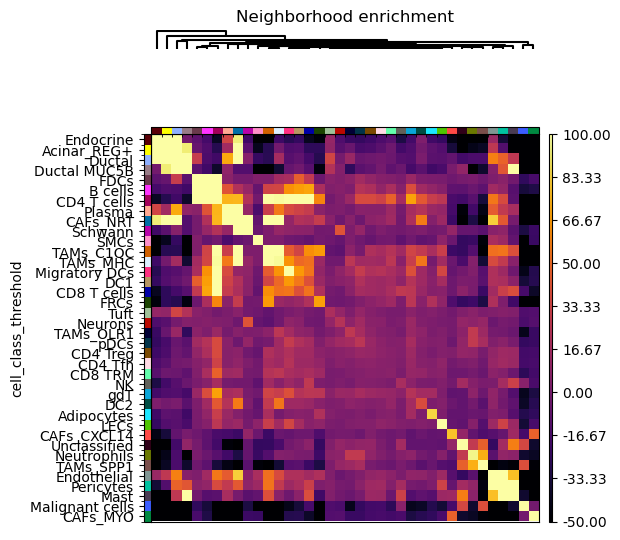

In [14]:
sq.gr.spatial_neighbors(adata, coord_type="generic", spatial_key="spatial", radius=RADIUS_UM)
sq.gr.nhood_enrichment(adata, cluster_key=LABEL_KEY, seed=NHOOD_SEED)
sq.pl.nhood_enrichment(adata, cluster_key=LABEL_KEY, method="average", cmap="inferno",
                       vmin=-50, vmax=100, figsize=(5, 5))

## 6. Save outputs

In [15]:
adata.write_h5ad(os.path.join(OUTPUT_DIR, f"{SAMPLE}.h5ad"))

# Values in this file are adata.X (log-normalised), not raw counts
metadata = pd.DataFrame({
    "x_location": adata.obs["x_centroid"].values,
    "y_location": adata.obs["y_centroid"].values,
    "cluster_based_annotation": adata.obs["anno"].values,
    "gene_set_scoring_annotation": adata.obs[LABEL_KEY].values,
    "transcript_counts": adata.obs["transcript_counts"].values,
}, index=adata.obs_names)
expression = pd.DataFrame(adata.X.toarray(), index=adata.obs_names, columns=adata.var_names)
pd.concat([metadata, expression], axis=1).to_csv(os.path.join(OUTPUT_DIR, f"{SAMPLE}.csv"), index=False)
del expression

## 7. Check against the saved object

In a passing run, `Same label` is 100%, the score difference is 0 and the Nhood correlation is 1.

In [17]:
reference = sc.read_h5ad(SAVED_OBJECT, backed="r")
assert list(adata.obs_names) == list(reference.obs_names), "Cells differ from the saved object"

same_label = (adata.obs[LABEL_KEY].astype(str).values == reference.obs[LABEL_KEY].astype(str).values).mean()
score_difference = np.abs(adata.obs[score_columns].values - reference.obs[score_columns].values).max()

key = f"{LABEL_KEY}_nhood_enrichment"
categories = list(adata.obs[LABEL_KEY].cat.categories)
reference_categories = list(reference.obs[LABEL_KEY].astype("category").cat.categories)
assert set(categories) == set(reference_categories), f"Labels differ: {sorted(set(categories) ^ set(reference_categories))}"
z_new = adata.uns[key]["zscore"]
z_reference = pd.DataFrame(reference.uns[key]["zscore"], index=reference_categories, columns=reference_categories).loc[categories, categories].values
valid = ~(np.isnan(z_new) | np.isnan(z_reference))

check = [
    ("Cells", adata.n_obs),
    ("Same label", f"{same_label:.4%}"),
    ("Gene-set scores, max difference", f"{score_difference:.3g}"),
    ("Nhood z-score correlation", f"{np.corrcoef(z_new[valid], z_reference[valid])[0, 1]:.4f}"),
    ("Nhood z-score, max difference", f"{np.abs(z_new[valid] - z_reference[valid]).max():.3g}"),
]
reference.file.close()

if os.path.exists(COUNTS_CSV):
    csv_labels = pd.read_csv(COUNTS_CSV, usecols=["gene_set_scoring"])["gene_set_scoring"]
    if len(csv_labels) == adata.n_obs:
        check.append(("Same label as counts CSV", f"{(csv_labels.astype(str).values == adata.obs[LABEL_KEY].astype(str).values).mean():.4%}"))

check = pd.DataFrame(check, columns=["measure", "value"])
check.to_csv(os.path.join(OUTPUT_DIR, "stage1_check.tsv"), sep="\t", index=False)
display(check)

,measure,value
0,Cells,214226
1,Same label,100.0000%
2,"Gene-set scores, max difference",0
3,Nhood z-score correlation,1.0000
4,"Nhood z-score, max difference",0
5,Same label as counts CSV,100.0000%
